# 08 — HSMM: Exploratory Fit, Baselines and Regime-Free Null

**Status: exploratory.** About 15 sessions per asset cannot support binding conclusions (board gate h1: 60–90 days). This notebook checks that the pipeline runs end to end on real data and shows roughly what structure the data supports. Nothing here selects $K$, the anchor or the emission family for production.

Model (Decisions part 2, §10–11), per asset in the contract universe:

$$
z_t = \mu_{s_t} + \beta_{s_t} D^c_{t-1} + \sum_{j=1}^{3}\rho_j z_{t-j} + \sigma_{s_t}\,\varepsilon_t, \qquad \varepsilon_t \sim t_\nu,
$$

$s_t$ an explicit-duration semi-Markov chain with negative-binomial episode lengths; $\rho_j$ shared by all states, so states cannot be labelled by the short-range reversal. $z_t = r_t/\sigma^c_{t-1}$; $D^c$ from the index EWMA anchor (half-life 1 h, $h_{\text{eff}}$-normalised, continuous across 08:00).

| Part | Question |
|---|---|
| A | Does the engine recover known regimes (self-test)? |
| B1 | **How many regimes does the data support?** $K = 1 \dots 6$ per asset, blocked cross-validation (framework Step 6) |
| B2 | At the selected $K$, does the HSMM beat no-regime and simpler regime baselines out of sample? |
| C | What do the fitted states look like — slopes, scales, durations — and are they just the clock? |
| D | Does the masked option block change the states (ablation)? |
| E | Are slope-separated states more pronounced than on regime-free paths (null)? |

$K$ is **not** fixed anywhere: Parts C–E use the $K$ selected in B1 for each asset (with $K \ge 2$ shown descriptively when B1 selects one regime). The noise state $Q_t$ of the framework is a separate two-state chain and is not part of $K$; it is not in this model yet (board gate z2).

Runtime on a desktop with `numba` installed: roughly 1–1.5 hours (selection ≈ 3 min per asset, the null dominates). Without numba the engine falls back to numpy and is several times slower. `HSMM_K_MAX`, `HSMM_NULL_PATHS` and `HSMM_NULL_ASSETS` change the workload.

In [1]:
from pathlib import Path
import os
import sys
import time
import itertools
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

load_dotenv()
DB_PATH = Path(os.environ["DERIBIT_DATA_ROOT"]).expanduser().resolve() / "database" / "research.duckdb"
con = duckdb.connect(str(DB_PATH), read_only=True)
con.execute("SET TimeZone = 'UTC'")

PROJECT_ROOT = Path(os.getenv("DERIBIT_PROJECT_ROOT", Path.cwd())).resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / "src" / "data_engineering").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src" / "data_engineering").exists():
    raise RuntimeError("Repository not found: start Jupyter inside the repository or set DERIBIT_PROJECT_ROOT.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from data_engineering.modeling.clock_baseline import ClockBaselineSet, FeatureSpec
from data_engineering.modeling.hsmm.engine import HSMMSpec, fit, episodes, ENGINE_VERSION, USE_NUMBA
from data_engineering.modeling.hsmm.selection import select_K, blocked_folds, MIN_EPISODES
from data_engineering.modeling.hsmm.design import build_design
from data_engineering.modeling.hsmm.baselines import compare_models
from data_engineering.modeling.hsmm.null import run_null, p_value
from data_engineering.modeling.hsmm import selftest

CONTRACT_ASSETS = ["AVAX", "BTC", "ETH", "HYPE", "SOL", "XRP"]       # contract v0 (TRX excluded)
NULL_PATHS = int(os.getenv("HSMM_NULL_PATHS", "25"))
NULL_ASSETS = os.getenv("HSMM_NULL_ASSETS", "BTC,ETH,SOL,XRP").split(",")
RUN_SELFTEST = os.getenv("HSMM_RUN_SELFTEST", "1") == "1"
K_MAX = int(os.getenv("HSMM_K_MAX", "6"))
FIT_KW = {"n_init": 2, "max_iter": 200, "tol": 1e-5}
print(f"Engine {ENGINE_VERSION} | numba {'on' if USE_NUMBA else 'OFF (slow: pip install numba)'} | "
      f"K = 1..{K_MAX} | null paths {NULL_PATHS} on {NULL_ASSETS}")

Engine 0.1.1 | numba on | K = 1..6 | null paths 25 on ['BTC', 'ETH', 'SOL', 'XRP']


## 1. Load and clock-adjust

In [2]:
cols = set(con.execute("DESCRIBE time_series_feature_state").df()["column_name"])
want = ["state_id", "state_time", "underlying", "session_id", "return_5m", "futures_index_price", "is_weekend",
        "utc_hour", "atm_iv_change_30m", "option_atm_quote_ok", "fit_skew_rel", "fit_curvature_rel", "fit_ok",
        "in_settlement_window"]
df = con.execute(f"SELECT {', '.join(c for c in want if c in cols)} FROM time_series_feature_state "
                 "ORDER BY underlying, state_time").df()
df["state_time"] = pd.to_datetime(df["state_time"], utc=True)
for c in ["is_weekend", "option_atm_quote_ok", "fit_ok", "in_settlement_window"]:
    if c in df:
        s = df[c]
        if s.dtype == object:
            s = s.map({"True": True, "False": False, True: True, False: False})
        df[c] = s.fillna(False).astype(bool)
df["r"] = pd.to_numeric(df["return_5m"], errors="coerce")
df["session_date"] = ((df["state_time"] - pd.Timedelta(hours=8)).dt.floor("D") + pd.Timedelta(days=1)).dt.strftime("%Y-%m-%d")
df = df[df["underlying"].isin(CONTRACT_ASSETS)].reset_index(drop=True)

dates = sorted(df.loc[df["r"].notna(), "session_date"].unique())
TRAIN_DATES = set(dates[: len(dates) // 2])
clock = ClockBaselineSet.fit(df[["state_id", "state_time", "underlying", "is_weekend", "return_5m"]],
                             df["session_date"].isin(TRAIN_DATES),
                             specs=(FeatureSpec("return_5m", "return_5m", transform="log_abs", scale="none"),))
df["f_clock"] = clock.transform(df[["state_id", "state_time", "underlying", "is_weekend", "return_5m"]])[
    "return_5m__clock_vol_factor"].to_numpy()
df["f_clock"] = df["f_clock"].fillna(1.0)
print(f"Rows {len(df):,} | assets {sorted(df.underlying.unique())} | sessions {len(dates)} | "
      f"train {min(TRAIN_DATES)} → {max(TRAIN_DATES)} | test {min(set(dates) - TRAIN_DATES)} → {max(dates)}")

Rows 29,376 | assets ['AVAX', 'BTC', 'ETH', 'HYPE', 'SOL', 'XRP'] | sessions 15 | train 2026-09-22 → 2026-09-28 | test 2026-09-29 → 2026-10-06


# Part A — Engine self-test

Synthetic data from a known two-state HSMM (opposite slopes, different scales and durations, shared lags, Student-$t$ noise, grid gaps). The engine must recover slopes, scales, shared terms and the state path; durations at strong separation; and a positive out-of-sample gain. On data without regimes it must not separate slopes. Note the likelihood ratio on regime-free data: it is far from zero, which is why the null in Part E uses slope separation, not the likelihood ratio.

In [3]:
if RUN_SELFTEST:
    t0 = time.perf_counter()
    status = selftest.main()
    print(f"self-test {'passed' if status == 0 else 'FAILED'} in {time.perf_counter() - t0:.0f}s")

[1] recovery: 20 EM iterations, 3.0s, converged=True
    beta_D  [-0.279  0.31 ]  true [-0.3   0.25]
    sigma   [0.718 0.934]  true [0.85 1.15]
    shared  [-0.06  -0.042 -0.012]  true [-0.04 -0.02 -0.01]
    nu 6.0  true 6.0 | mean duration [21.7 22.7]  true [24. 40.]
    state accuracy 0.807
    (durations at realistic strength are biased short: [0.91 0.57] of true)
[1b] strong separation: mean duration [24.2 38.8] vs realised [23.8 37.7], accuracy 0.971
[3] out-of-sample log score gain K=2 vs K=1: 0.0182 per bar
[2] no regimes: slope spread 0.068 (regime data: 0.590), LR vs K=1 13.9 (regime data: 238.6)
HSMM SELF-TEST PASSED
self-test passed in 9s


## 2. Design per asset

Rows need $z_t$, $D^c_{t-1}$ and three lagged $z$ on a contiguous grid; contiguous runs of at least 24 rows form segments. The option block (Part D) is the 30-minute change of the quote-backed fixed-k ATM IV, and the quote-only fitted skew and curvature levels, each standardized on the training sessions and masked when unavailable (late session, weekends, settlement window).

In [4]:
designs = {}
rows = []
for asset, g in df.groupby("underlying"):
    g = g.sort_values("state_time").reset_index(drop=True)
    tr_mask = g["session_date"].isin(TRAIN_DATES)
    blk = pd.DataFrame(index=g.index)
    msk = pd.DataFrame(index=g.index)
    active = ~g["in_settlement_window"] if "in_settlement_window" in g else True
    if "atm_iv_change_30m" in g:
        blk["atm_change_30m"] = pd.to_numeric(g["atm_iv_change_30m"], errors="coerce")
        msk["atm_change_30m"] = g.get("option_atm_quote_ok", True) & active
    for c in ["fit_skew_rel", "fit_curvature_rel"]:
        if c in g:
            blk[c] = pd.to_numeric(g[c], errors="coerce")
            msk[c] = g.get("fit_ok", True) & active
    for c in blk.columns:
        m, s = blk.loc[tr_mask & msk[c], c].mean(), blk.loc[tr_mask & msk[c], c].std()
        blk[c] = (blk[c] - m) / (s if s and np.isfinite(s) else 1.0)
        msk[c] = msk[c] & blk[c].notna()
    d = build_design(g, g["f_clock"].to_numpy(), block=blk if len(blk.columns) else None,
                     block_mask=msk if len(blk.columns) else None)
    designs[asset] = (d, g)
    fr = d.frame
    rows.append({"underlying": asset, "rows": len(fr), "segments": len(d.starts),
                 "train_rows": int(fr.session_date.isin(TRAIN_DATES).sum()),
                 "sd_y": fr.y.std(), "sd_D": fr.D.std(), "corr_D_z1": fr[["D", "z1"]].corr().iloc[0, 1],
                 "block_obs_share": float(d.block_mask.any(axis=1).mean()) if d.block_mask is not None else 0.0})
design_summary = pd.DataFrame(rows).set_index("underlying")
display(design_summary.round(3))

,rows,segments,train_rows,sd_y,sd_D,corr_D_z1,block_obs_share
underlying,,,,,,,
AVAX,3419,29,1641,1.084,0.836,0.343,0.910
BTC,3419,29,1641,1.097,0.824,0.349,0.914
ETH,3419,29,1641,1.121,0.763,0.350,0.918
HYPE,3419,29,1641,1.079,0.873,0.329,0.896
SOL,3419,29,1641,1.113,0.829,0.347,0.854
XRP,3419,29,1641,1.101,0.797,0.353,0.822


# Part B1 — How many regimes? (framework Step 6)

Expanding-window cross-validation over whole sessions (3 folds; the first ≈ 45% of sessions are always training). For each $K = 1 \dots K_{max}$ the HSMM is fitted on each training window and scored on the following test block by the one-step predictive log density:

$$
\mathcal{L}_{OOS}(K) = \sum_{\text{folds}} \sum_{t \in \text{test}} \log \sum_{k=1}^{K} P(R_t = k \mid \mathcal{F}_{t-1})\, p_k(y_t \mid \mathcal{F}_{t-1})
$$

Selection rule, fixed in advance:

1. **One-standard-error rule:** admissible are the $K$ whose $\mathcal{L}_{OOS}$ is within one standard error of the best, the standard error being that of the per-session score difference summed over test sessions.
2. **Support:** every state of a full-sample fit must have at least 20 episodes (framework acceptance criterion).

The selected $K$ is the smallest $K$ satisfying both; if none does, the best-scoring $K$ with support. `K_best` (the unrestricted maximum of $\mathcal{L}_{OOS}$) is shown as well.

Validation on synthetic data generated from the model: three true regimes → $K = 3$ selected ($K = 4, 5$ gained 2–6 nats by splitting off thin states with 12–16 episodes and failed the support rule); no regimes → $K = 1$.

**Caveat found during validation.** When the true volatility jumps between regimes, the EWMA scale $\sigma^c$ adapts with a lag, so standardized returns carry a decaying volatility burst after each switch, and extra states can absorb it: on price-space synthetic data with three true regimes, $\mathcal{L}_{OOS}$ kept rising up to $K = 6$. A high selected $K$ is therefore **not** evidence of displacement regimes by itself; Parts C (per-state $\beta$ vs $\sigma$) and E (null) decide that.

In [5]:
print("Folds:", [(len(tr), sorted(te)) for tr, te in blocked_folds(sorted(df.loc[df.r.notna(), "session_date"].unique()))])
selection, sel_tables, K_SEL = {}, [], {}
for asset, (d, g) in designs.items():
    t0 = time.perf_counter()
    K_sel, tab, info = select_K(d, K_values=tuple(range(1, K_MAX + 1)), spec_kw=FIT_KW, verbose=False)
    K_SEL[asset] = K_sel
    selection[asset] = info
    sel_tables.append(tab.reset_index().assign(underlying=asset))
    print(f"{asset}: selected K = {K_sel}, best-scoring K = {int(tab.oos_logscore.idxmax())} ({time.perf_counter() - t0:.0f}s)")
k_selection = pd.concat(sel_tables, ignore_index=True)
print("Out-of-sample log score relative to the best K (nats, summed over test sessions):")
display(k_selection.pivot(index="K", columns="underlying", values="diff_vs_best").round(1))
print("One standard error of that difference:")
display(k_selection.pivot(index="K", columns="underlying", values="se_diff").round(1))
print("Episodes per state in the full-sample fit (support needs >= 20 each):")
display(k_selection.pivot(index="K", columns="underlying", values="episodes_per_state"))
print("Selected K:", K_SEL)
K_USE = {a: max(k, 2) for a, k in K_SEL.items()}       # K >= 2 for the descriptive parts

Folds: [(7, ['2026-09-29', '2026-09-30', '2026-10-01']), (10, ['2026-10-02', '2026-10-03', '2026-10-04']), (13, ['2026-10-05', '2026-10-06'])]
AVAX: selected K = 1, best-scoring K = 2 (154s)
BTC: selected K = 2, best-scoring K = 2 (161s)
ETH: selected K = 1, best-scoring K = 2 (150s)
HYPE: selected K = 1, best-scoring K = 1 (127s)
SOL: selected K = 1, best-scoring K = 2 (140s)
XRP: selected K = 1, best-scoring K = 1 (147s)
Out-of-sample log score relative to the best K (nats, summed over test sessions):


underlying,AVAX,BTC,ETH,HYPE,SOL,XRP
K,,,,,,
1,-3.4,-8.9,-0.8,0.0,-2.1,0.0
2,0.0,0.0,0.0,-7.5,0.0,-2.7
3,-3.7,-8.3,-22.7,-12.8,-7.9,-2.6
4,-7.6,-4.1,-29.2,-15.5,-19.1,-6.8
5,-12.8,-23.6,-16.8,-16.9,-21.8,-10.1
6,-14.3,-25.5,-35.3,-29.5,-30.8,-12.8


One standard error of that difference:


underlying,AVAX,BTC,ETH,HYPE,SOL,XRP
K,,,,,,
1,4.1,6.5,4.8,0.0,7.2,0.0
2,0.0,0.0,0.0,5.1,0.0,6.8
3,2.7,6.8,7.4,5.8,3.8,8.5
4,4.9,5.8,9.1,6.7,9.9,9.8
5,7.0,14.6,6.2,7.2,7.8,9.8
6,8.8,13.6,13.8,8.2,9.2,11.1


Episodes per state in the full-sample fit (support needs >= 20 each):


underlying,AVAX,BTC,ETH,HYPE,SOL,XRP
K,,,,,,
1,None,None,None,None,None,None
2,"[155, 144]","[205, 218]","[96, 106]","[354, 370]","[165, 176]","[216, 219]"
3,"[191, 120, 77]","[229, 86, 282]","[96, 171, 54]","[54, 33, 87]","[117, 157, 201]","[584, 351, 272]"
4,"[311, 66, 175, 177]","[131, 153, 145, 117]","[27, 36, 97, 64]","[116, 263, 30, 364]","[237, 96, 28, 236]","[381, 7, 264, 139]"
5,"[194, 396, 63, 521, 60]","[99, 82, 123, 141, 130]","[133, 152, 50, 304, 33]","[167, 48, 260, 34, 384]","[290, 86, 52, 13, 223]","[495, 76, 1, 492, 107]"
6,"[445, 82, 104, 342, 85, 157]","[25, 72, 76, 163, 198, 170]","[238, 46, 306, 6, 551, 45]","[161, 461, 149, 50, 339, 233]","[329, 142, 264, 127, 195, 43]","[84, 169, 389, 1, 321, 129]"


Selected K: {'AVAX': 1, 'BTC': 2, 'ETH': 1, 'HYPE': 1, 'SOL': 1, 'XRP': 1}


# Part B2 — Out-of-sample comparison with baselines

Every model is fitted on the first half of sessions and scored on the second half by the one-step predictive log density of $z_t$ (same rows for all models). The HSMM is shown at $K = 2$ and at the selected $K$ of each asset. Gains are relative to the no-regime model with lags only, in thousandths of a nat per bar; $t$ uses Newey–West (12 lags). The 15-session window is short, so a gain must be large to be distinguishable from noise.

In [6]:
cmp_rows, cmp_info = [], {}
for asset, (d, g) in designs.items():
    t0 = time.perf_counter()
    tr = d.frame["session_date"].isin(TRAIN_DATES).to_numpy()
    tab, info = compare_models(d, tr, ~tr, spec_kw=FIT_KW, hsmm_K=tuple(sorted({2, K_USE[asset]})))
    cmp_rows.append(tab.assign(underlying=asset))
    cmp_info[asset] = info
    print(f"{asset}: {time.perf_counter() - t0:.0f}s")
comparison = pd.concat(cmp_rows, ignore_index=True)
print("Gain vs no-regime (lags only), x1000 nats per bar:")
display(comparison.pivot(index="model", columns="underlying", values="gain_vs_no_regime_x1000").round(1))
print("Newey-West t of the gain:")
display(comparison.pivot(index="model", columns="underlying", values="hac_t").round(2))

AVAX: 7s
BTC: 4s
ETH: 3s
HYPE: 4s
SOL: 3s
XRP: 5s
Gain vs no-regime (lags only), x1000 nats per bar:


underlying,AVAX,BTC,ETH,HYPE,SOL,XRP
model,,,,,,
hsmm_K2,2.9,5.6,-1.7,-10.8,3.4,1.9
jump_K2,-22.7,-110.1,-111.6,-83.8,-73.4,-3.3
ms_ar1_K2,-0.8,8.8,0.4,-0.7,1.7,3.9
no_regime_D,0.2,-1.1,-1.9,-1.1,-0.4,1.7
no_regime_lags,0.0,0.0,0.0,0.0,0.0,0.0
rule_vr3,-2.5,-4.7,-2.1,-5.0,-2.3,3.1
sticky_hmm_K2,1.5,5.9,-0.8,-4.5,2.5,3.7


Newey-West t of the gain:


underlying,AVAX,BTC,ETH,HYPE,SOL,XRP
model,,,,,,
hsmm_K2,1.18,1.31,-0.47,-2.20,1.04,0.45
jump_K2,-4.10,-7.41,-6.20,-5.43,-5.71,-0.97
ms_ar1_K2,-0.27,3.00,0.13,-0.46,0.72,1.31
no_regime_D,1.06,-0.59,-0.73,-0.60,-0.21,2.23
no_regime_lags,0.00,0.00,0.00,0.00,0.00,0.00
rule_vr3,-1.20,-1.67,-0.62,-1.55,-0.83,1.32
sticky_hmm_K2,0.65,1.63,-0.21,-1.75,0.81,0.95


# Part C — Fitted states (full sample, selected K)

Full-sample fits at the selected $K$ of each asset ($K = 2$, marked *not selected*, where B1 selected one regime), for description only. States are ordered by the displacement slope (state 0: lowest $\beta$). States that differ mainly in $\sigma$ with similar $\beta$ are volatility (or scale-lag) states, not displacement regimes. The clock check reports $\eta^2$ of the posterior-mode state on hour × weekend: a value near the clock's own explanatory power would mean the states are relabelling the deterministic clock (which the clock baseline should already have removed).

In [7]:
def eta2(y, g):
    d = pd.DataFrame({"y": y, "g": g}).dropna()
    gm = d.groupby("g")["y"].transform("mean")
    sst = ((d.y - d.y.mean()) ** 2).sum()
    return float(((gm - d.y.mean()) ** 2).sum() / sst) if sst > 0 else np.nan


full_fits, state_rows, ep_rows = {}, [], []
for asset, (d, g) in designs.items():
    data = d.data()
    K = K_USE[asset]
    res = fit(data, HSMMSpec(K=K, n_init=4, max_iter=300, seed=1))
    full_fits[asset] = res
    p = res.params
    lab = res.gamma.argmax(axis=1)
    fr = d.frame
    hour = pd.to_datetime(fr["state_time"], utc=True).dt.hour.to_numpy()
    wk = pd.to_datetime(fr["state_time"], utc=True).dt.dayofweek.to_numpy() >= 5
    for k in range(K):
        state_rows.append({"underlying": asset, "K": K, "K_selected": K_SEL[asset], "state": k,
                           "beta_D": p.beta_s[k, 1], "mu": p.beta_s[k, 0],
                           "sigma": p.sigma[k], "mean_duration_bars": p.mean_duration()[k],
                           "occupancy": float((lab == k).mean()), "nu": p.nu,
                           "shared_lags": np.round(p.beta_c, 3).tolist(),
                           "clock_eta2": eta2((lab == k).astype(float), hour * 2 + wk)})
    for e in episodes(res.gamma, data):
        ep_rows.append({"underlying": asset, **e})
states = pd.DataFrame(state_rows)
display(states.round(3))
eps = pd.DataFrame(ep_rows)
display(eps.groupby(["underlying", "state"]).agg(episodes=("length", "size"), uncensored=("censored", lambda c: int((~c).sum())),
                                                  median_bars=("length", "median"), p90_bars=("length", lambda v: v.quantile(0.9))))

,underlying,K,K_selected,state,beta_D,mu,sigma,mean_duration_bars,occupancy,nu,shared_lags,clock_eta2
0,AVAX,2,1,0,-0.182,-0.099,0.623,4.469,0.395,5.0,"[-0.058, -0.029, -0.013]",0.057
1,AVAX,2,1,1,0.083,0.076,0.959,5.991,0.605,5.0,"[-0.058, -0.029, -0.013]",0.057
2,BTC,2,2,0,-0.203,-0.024,0.644,4.222,0.708,5.0,"[-0.049, -0.009, 0.005]",0.053
3,BTC,2,2,1,0.165,0.082,1.077,2.963,0.292,5.0,"[-0.049, -0.009, 0.005]",0.053
4,ETH,2,1,0,-0.191,-0.009,0.663,11.060,0.478,5.0,"[-0.048, 0.006, -0.014]",0.123
5,ETH,2,1,1,-0.015,0.025,0.971,11.451,0.522,5.0,"[-0.048, 0.006, -0.014]",0.123
6,HYPE,2,1,0,-0.271,-0.013,0.692,1.955,0.491,8.0,"[-0.028, 0.014, -0.002]",0.031
7,HYPE,2,1,1,0.161,0.008,1.043,2.401,0.509,8.0,"[-0.028, 0.014, -0.002]",0.031
8,SOL,2,1,0,-0.231,-0.018,0.715,3.640,0.860,6.0,"[-0.024, -0.017, -0.012]",0.024
9,SOL,2,1,1,0.388,0.107,1.133,1.634,0.140,6.0,"[-0.024, -0.017, -0.012]",0.024


episodes  uncensored  median_bars  p90_bars
underlying state                                             
AVAX       0           196         160          4.0      18.0
           1           188         167          6.0      29.3
BTC        0           337         317          3.0      20.0
           1           346         308          2.0       7.0
ETH        0           104          91         10.0      33.7
           1           120          78         11.0      33.0
HYPE       0           782         766          1.0       5.0
           1           795         753          1.0       5.0
SOL        0           356         329          4.0      23.0
           1           358         327          1.0       2.0
XRP        0            97          64         27.0      71.4
           1            93          68          1.0       3.0

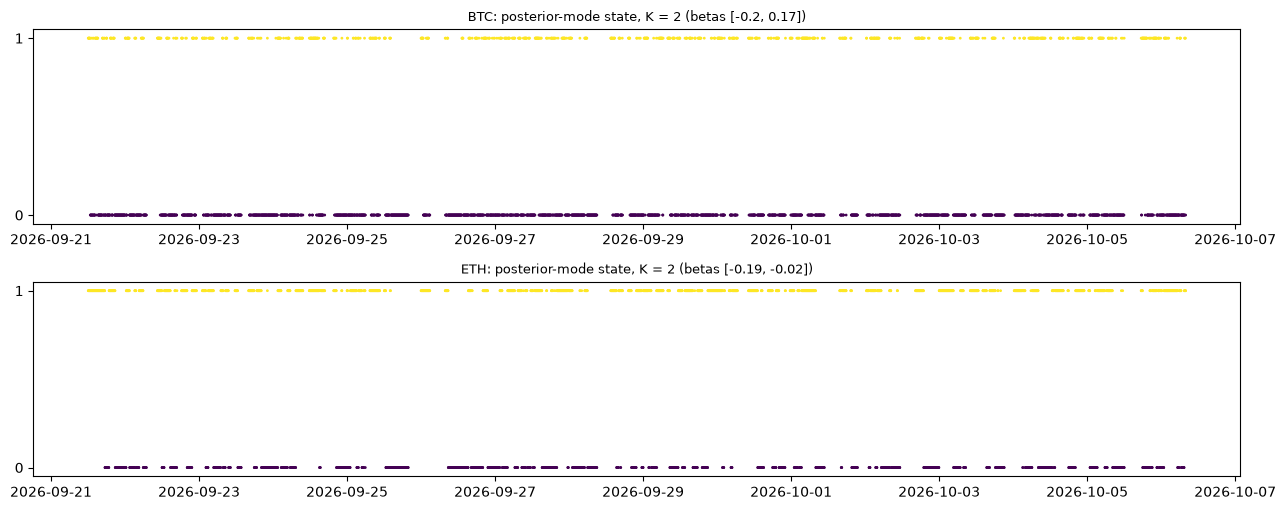

In [8]:
if designs:
    show = [a for a in ["BTC", "ETH"] if a in designs] or list(designs)[:2]
    fig, axes = plt.subplots(len(show), 1, figsize=(13, 2.6 * len(show)), squeeze=False)
    for ax, asset in zip(axes[:, 0], show):
        d, _ = designs[asset]
        res = full_fits[asset]
        t = pd.to_datetime(d.frame["state_time"], utc=True)
        lab = res.gamma.argmax(axis=1)
        ax.scatter(t, lab, s=1, c=lab, cmap="viridis")
        ax.set_yticks(range(res.params.K))
        ax.set_title(f"{asset}: posterior-mode state, K = {res.params.K} (betas {np.round(res.params.beta_s[:, 1], 2).tolist()})", fontsize=9)
    plt.tight_layout(); plt.show()

# Part D — Option-block ablation

The same model (selected $K$) with the masked option block added to the emission. If the block dominates the state assignment (agreement with the structural states near 50%), the states would be defined by the option surface rather than by price dynamics, which the framework forbids (§7: states must survive without the option block). Agreement is computed between posterior-mode paths after the best label matching.

In [9]:
abl_rows = []
for asset, (d, g) in designs.items():
    if d.block is None:
        continue
    data_b = d.data(with_block=True)
    K = K_USE[asset]
    res_b = fit(data_b, HSMMSpec(K=K, n_init=4, max_iter=300, seed=1))
    lab_s = full_fits[asset].gamma.argmax(axis=1)
    lab_b = res_b.gamma.argmax(axis=1)
    agree = max(float((lab_s == np.asarray(perm)[lab_b]).mean()) for perm in itertools.permutations(range(K)))
    abl_rows.append({"underlying": asset, "K": K, "agreement_with_structural": agree, "chance_level": 1.0 / K,
                     "beta_D_with_block": np.round(res_b.params.beta_s[:, 1], 3).tolist(),
                     "beta_D_structural": np.round(full_fits[asset].params.beta_s[:, 1], 3).tolist(),
                     "block_means_state0": np.round(res_b.params.m[0], 2).tolist(),
                     "block_means_state1": np.round(res_b.params.m[1], 2).tolist(),
                     "mean_duration_with_block": np.round(res_b.params.mean_duration(), 1).tolist()})
ablation = pd.DataFrame(abl_rows)
display(ablation)

,underlying,K,agreement_with_structural,chance_level,beta_D_with_block,beta_D_structural,block_means_state0,block_means_state1,mean_duration_with_block
0,AVAX,2,0.525007,0.5,"[-0.041, -0.007]","[-0.182, 0.083]","[-0.05, -0.12, -0.06]","[0.08, -0.05, -0.62]","[18.8, 12.9]"
1,BTC,2,0.603978,0.5,"[-0.073, -0.037]","[-0.203, 0.165]","[-0.09, 0.26, -0.29]","[0.18, -0.84, 0.45]","[57.4, 29.4]"
2,ETH,2,0.529687,0.5,"[-0.123, -0.081]","[-0.191, -0.015]","[0.1, -1.6, 1.38]","[-0.04, 0.1, -0.21]","[38.7, 57.3]"
3,HYPE,2,0.517403,0.5,"[-0.058, -0.055]","[-0.271, 0.161]","[0.04, 0.46, -0.02]","[-0.05, -0.98, -0.29]","[36.0, 34.5]"
4,SOL,2,0.555426,0.5,"[-0.137, -0.015]","[-0.231, 0.388]","[-0.03, -1.03, 0.32]","[-0.01, 0.6, -0.76]","[35.0, 30.0]"
5,XRP,2,0.713951,0.5,"[-0.122, -0.026]","[-0.178, 0.658]","[-0.05, -0.04, -0.89]","[0.08, 0.1, -0.19]","[41.0, 18.5]"


# Part E — Regime-free null

For each asset in `HSMM_NULL_ASSETS`, `HSMM_NULL_PATHS` paths of two regime-free nulls are passed through the identical pipeline and refitted with K = 1 and the asset's selected $K$ (at least 2):

- **sign**: real return magnitudes with random signs. Keeps every volatility shock exactly, including the ones the EWMA scale misses; removes all sign dependence.
- **ar_bootstrap**: AR(3) standardized returns with bootstrapped innovations on the EWMA volatility path. Keeps the short-range reversal; smooths volatility shocks.

Validation on synthetic regime-free data showed the null distribution of the slope separation is bimodal (EM finds either a degenerate split, $\Delta\beta \approx 0.01$, or a weak one, $\approx 0.1$), and that a handful of paths can falsely reject. **Displacement regimes require rejection under both nulls.**

The decision statistic is the **slope separation** $\Delta\beta = \max_k\beta_k - \min_k\beta_k$. The likelihood ratio is reported but is not a regime test here (volatility clustering alone inflates it). One-sided empirical p-value $p = (1 + \#\{\Delta\beta^* \ge \Delta\hat\beta\}) / (1 + N)$; with 25 paths the smallest attainable p is 0.038.

In [10]:
null_rows, null_draws = [], []
for asset in NULL_ASSETS:
    if asset not in designs:
        continue
    d, g = designs[asset]
    for kind in ["sign", "ar_bootstrap"]:
        t0 = time.perf_counter()
        real, draws = run_null(g, g["f_clock"].to_numpy(), TRAIN_DATES, NULL_PATHS, kind=kind,
                               spec=HSMMSpec(K=K_USE[asset], seed=3, **FIT_KW), seed=sum(map(ord, asset)), oos=False)
        null_draws.append(draws.assign(underlying=asset, null=kind))
        null_rows.append({"underlying": asset, "null": kind, "K": K_USE[asset], "beta_spread_real": real["beta_spread"],
                          "beta_spread_null_p50": draws.beta_spread.median(), "beta_spread_null_p95": draws.beta_spread.quantile(0.95),
                          "p_beta_spread": p_value(real["beta_spread"], draws.beta_spread),
                          "lr_real": real["lr"], "lr_null_p50": draws.lr.median(), "p_lr": p_value(real["lr"], draws.lr),
                          "sigma_ratio_real": real["sigma_ratio"], "sigma_ratio_null_p50": draws.sigma_ratio.median(),
                          "seconds": time.perf_counter() - t0})
null_test = pd.DataFrame(null_rows)
display(null_test.round(3))
if len(null_test):
    both = null_test.pivot(index="underlying", columns="null", values="p_beta_spread")
    both["rejects_both"] = (both.max(axis=1) <= 0.05)
    print("Slope-separation p-values; displacement regimes need rejection under both nulls:")
    display(both.round(3))

  BTC: 10/25 null paths
  BTC: 20/25 null paths
  BTC: 10/25 null paths
  BTC: 20/25 null paths
  ETH: 10/25 null paths
  ETH: 20/25 null paths
  ETH: 10/25 null paths
  ETH: 20/25 null paths
  SOL: 10/25 null paths
  SOL: 20/25 null paths
  SOL: 10/25 null paths
  SOL: 20/25 null paths
  XRP: 10/25 null paths
  XRP: 20/25 null paths
  XRP: 10/25 null paths
  XRP: 20/25 null paths


,underlying,null,K,beta_spread_real,beta_spread_null_p50,beta_spread_null_p95,p_beta_spread,lr_real,lr_null_p50,p_lr,sigma_ratio_real,sigma_ratio_null_p50,seconds
0,BTC,sign,2,0.295,0.031,0.115,0.038,41.206,22.197,0.038,1.624,1.493,33.745
1,BTC,ar_bootstrap,2,0.295,0.036,0.138,0.038,41.206,29.804,0.269,1.624,1.710,54.553
2,ETH,sign,2,0.177,0.043,0.130,0.038,19.647,13.713,0.038,1.443,1.387,26.947
3,ETH,ar_bootstrap,2,0.177,0.038,0.099,0.038,19.647,39.065,0.846,1.443,1.703,50.667
4,SOL,sign,2,0.313,0.082,0.245,0.038,29.020,9.814,0.038,1.563,1.303,32.453
5,SOL,ar_bootstrap,2,0.313,0.044,0.175,0.038,29.020,34.635,0.692,1.563,1.731,59.529
6,XRP,sign,2,0.326,0.051,0.109,0.038,33.398,18.618,0.038,1.570,1.453,32.927
7,XRP,ar_bootstrap,2,0.326,0.047,0.103,0.038,33.398,23.811,0.269,1.570,1.544,51.256


Slope-separation p-values; displacement regimes need rejection under both nulls:


null,ar_bootstrap,sign,rejects_both
underlying,,,
BTC,0.038,0.038,True
ETH,0.038,0.038,True
SOL,0.038,0.038,True
XRP,0.038,0.038,True


## Interpretation checklist

| Result | Implication |
|---|---|
| A: self-test passed | The engine is correct; real-data results are about the data. |
| B1: selected $K \ge 4$ on several majors | The data supports more than three structural states — consistent with the hypothesis, but only meaningful if C shows distinct $\beta_k$ (not only $\sigma_k$) and E rejects. |
| B1: selected $K = 1$ | No regime structure is identifiable at 15 sessions; re-run at 60 days. |
| B2: HSMM gain over `no_regime_D` with $|t| > 2$ on several assets | Regimes add predictive information beyond lags and unconditional displacement. |
| B2: HSMM ≈ sticky HMM | Duration dependence adds nothing yet (expected with ~55 episodes per state). |
| B2: HSMM gain ≈ gain of the regime models without D (MS-AR) | The gain is volatility regimes, not displacement regimes. |
| C: $\beta$ of opposite sign across states, uncensored episodes in the tens | Candidate mean-reversion/momentum states — only meaningful if E rejects. |
| C: high clock $\eta^2$ | States relabel the clock; the baseline is incomplete. |
| D: agreement well below the structural fit | The option block drives the states; it must stay out of the state definition. |
| E: $p(\Delta\beta) \le 0.05$ under **both** nulls on several majors | Slope-separated states are stronger than regime-free paths produce: evidence for displacement regimes. |
| E: $p(\Delta\beta)$ large | No evidence yet; at 15 sessions this is the expected outcome. Re-run at 60 days. |

In [11]:
hsmm_report = {"design": design_summary.reset_index(), "k_selection": k_selection, "comparison": comparison, "states": states,
               "episodes": eps, "ablation": ablation, "null_test": null_test,
               "null_draws": pd.concat(null_draws, ignore_index=True) if null_draws else pd.DataFrame()}
for k, v in hsmm_report.items():
    print(f"  {k:<12} {len(v):>7,} rows")
con.close()
print("DuckDB connection closed.")

  design             6 rows
  k_selection       36 rows
  comparison        42 rows
  states            12 rows
  episodes       3,772 rows
  ablation           6 rows
  null_test          8 rows
  null_draws       200 rows
DuckDB connection closed.
